# Trap Frequency Measurement Test

In [58]:
from pytweezer.servers.device_client import get_device
from pytweezer.drivers.motmaster import MotMasterInterface
from pytweezer.drivers.imagemX2 import ImagEMX2Camera
from pytweezer.drivers.slm import SLM
import numpy as np
from pytweezer.experiment.experiment_parameter_manager import ExpParameterManager
ExpParams = ExpParameterManager()
import pytweezer.analysis.analysis as an
import matplotlib.pyplot as plt

In [2]:
slm = get_device("Rb SLM")
exp: MotMasterInterface = get_device("Rb MOTMaster")
hamcam: ImagEMX2Camera = get_device("Rb HamCam")

In [6]:
exp.set_save_toggle(False)
exp.set_run_until_stopped(False)
exp.set_motmaster_experiment("RbTweezerBasic2026_2")

hamcam.set_trigger_source("ext")
hamcam.set_external_exposure_mode()
hamcam.enable_em_gain(True)
hamcam.enable_direct_em_gain(True)
hamcam.set_sensitivity(600)
hamcam.timeout = 60*5
X0, Y0, WIDTH, HEIGHT = 65, 120, 256, 256
hamcam.set_roi(X0, WIDTH, Y0, HEIGHT)

(64, 112)

---

In [10]:
from pytweezer.experiment.client import get_saved_parameter, get_saved_parameters

In [24]:
exp_params

{'caf_laser_BX': 564.5823400370625,
 'caf_laser_TCool': 564.5820055090313,
 'caf_laser_v0': 494.43239275060836,
 'caf_laser_v1': 476.95891310441954,
 'caf_laser_v2': 477.29940162357025,
 'caf_laser_v3': 477.6281810581851,
 'cafmot_cam_binning': 4,
 'cafmot_cam_exposure': 0.011218088235294117,
 'cafmot_cam_exposure_mode': 'edge',
 'cafmot_cam_roi_height': 496,
 'cafmot_cam_roi_width': 672,
 'cafmot_cam_roi_x0': 896,
 'cafmot_cam_roi_y0': 768,
 'cafmot_cam_trigger_polarity': 'fall',
 'cafmot_cam_trigger_source': 'ext',
 'orca_exposure': 0.004999999888241291,
 'orca_exposure_mode': 'edge',
 'orca_frame_rate': 8.52254084214635,
 'orca_gain': 0,
 'orca_roi_height': 96,
 'orca_roi_width': 96,
 'orca_roi_x0': 656,
 'orca_roi_y0': 496,
 'orca_trigger_source': 'ext',
 'rb_hamcam_direct_em_gain': False,
 'rb_hamcam_em_gain': False,
 'rb_hamcam_exposure': 0.4000000059604645,
 'rb_hamcam_exposure_mode': 'level',
 'rb_hamcam_frame_rate': 1.0,
 'rb_hamcam_gain': 610,
 'rb_hamcam_roi_height': 512,
 '

In [ ]:
exp_params = get_saved_parameters()

params = {}
for key in exp_params.keys():
    if "tMol" in key:
        params[f"{key}"] = exp_params[key]

params["tImgCoolVCO1"] = 2.0
params["tImgCoolVCO2"] = 2.0
params["tImgCoolVVA1"] = exp_params["tImgCoolVVA"]
params["tImgCoolVVA2"] = exp_params["tImgCoolVVA"]
params["BackgroundDrop"] = 1
params["tDelay2"] = 1000
params["tDropDuration"] = 1000

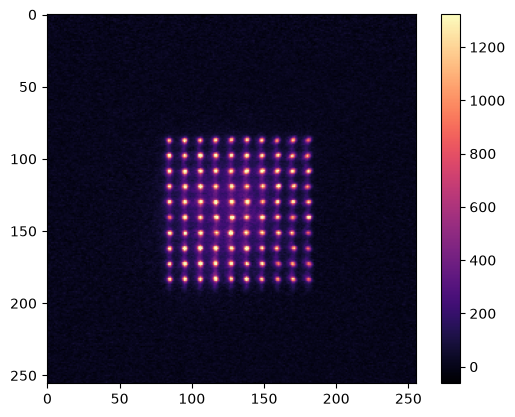

In [48]:
# Experiment and camera setup
n_iterations = 100
exp.set_motmaster_experiment("RbTweezerBasic2026_2")
exp.set_iterations(1)
hamcam.setup_acquisition(2)
imgs1, imgs2 = [], []
for i in range(n_iterations):
    hamcam.start_acquisition()
    exp.start_motmaster_experiment(params)

    img1, img2 = hamcam.acquire_n_frames(2, broadcast=True)
    imgs1.append(img1)
    imgs2.append(img2)
img_average = an.tweezer_show_bg_subtracted(imgs1, imgs2, cmap='magma', show=True, vmaxfactor=0.6, show_grid=True)

Looking for trap sites...
100 Atoms Detected.


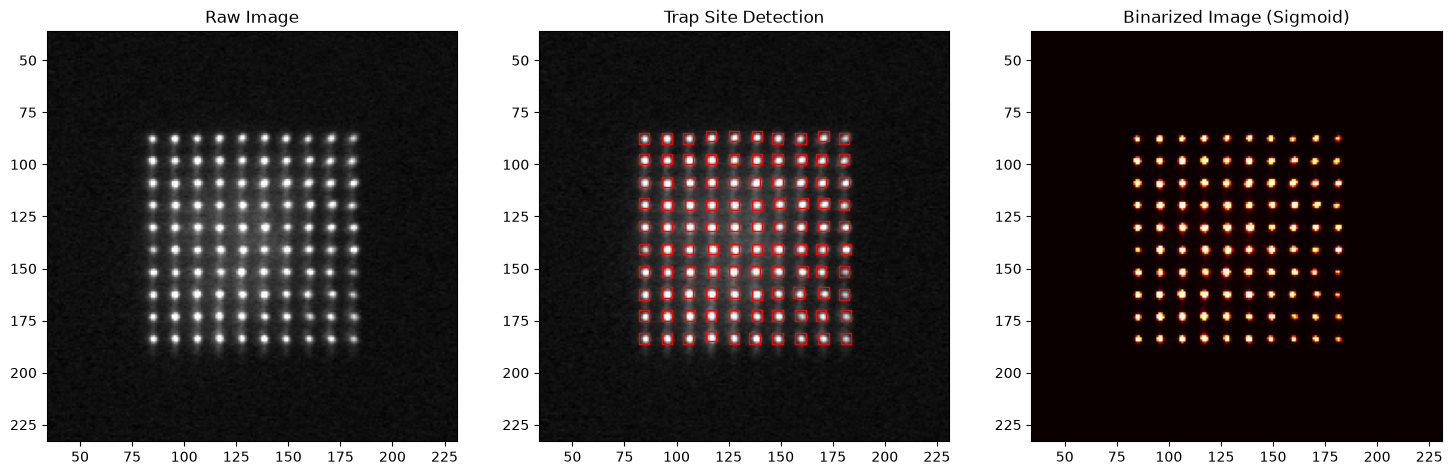

Trap (0) Loading Probability : 58.00 %
Trap (1) Loading Probability : 46.00 %
Trap (2) Loading Probability : 50.00 %
Trap (3) Loading Probability : 46.00 %
Trap (4) Loading Probability : 54.00 %
Trap (5) Loading Probability : 53.00 %
Trap (6) Loading Probability : 57.00 %
Trap (7) Loading Probability : 51.00 %
Trap (8) Loading Probability : 45.00 %
Trap (9) Loading Probability : 48.00 %
Trap (10) Loading Probability : 67.00 %
Trap (11) Loading Probability : 58.00 %
Trap (12) Loading Probability : 63.00 %
Trap (13) Loading Probability : 51.00 %
Trap (14) Loading Probability : 52.00 %
Trap (15) Loading Probability : 52.00 %
Trap (16) Loading Probability : 54.00 %
Trap (17) Loading Probability : 56.00 %
Trap (18) Loading Probability : 59.00 %
Trap (19) Loading Probability : 56.00 %
Trap (20) Loading Probability : 55.00 %
Trap (21) Loading Probability : 53.00 %
Trap (22) Loading Probability : 45.00 %
Trap (23) Loading Probability : 61.00 %
Trap (24) Loading Probability : 61.00 %
Trap (25) 

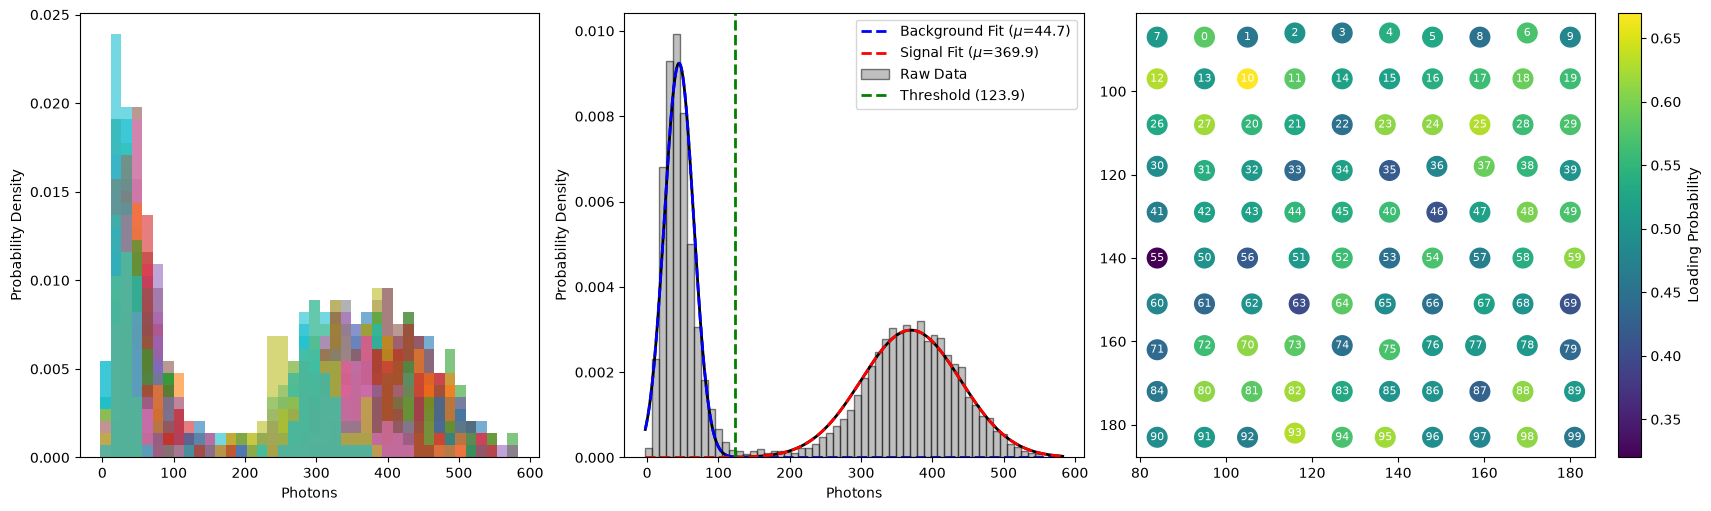

In [49]:
feature_size, window = 10, 5
grid_positions, detection_threshold = an.detect_trap_sites(img_average, 10*10, detection_step=100)
an.visualize_results(img_average, grid_positions, margin=50, window_size=window, threshold=detection_threshold, vmaxfactor=0.5, bin_sharpness=20, bin_thresh_factor=0.9)
imgs_n_filtered = [an.morphological_tophat_high_pass(img, feature_size=feature_size) for img in imgs1]
photons, loading_probabilities, threshold_1, fidelity = an.get_array_loading_statistics(imgs_n_filtered, grid_positions, threshold=100, window_size=5, binning=60, 
                                                                                        show_histogram=True, threshold_detection=True, verbose=True, show_site_labels=True)

---
## Extracting Survival Probability

In [ ]:

params["tImgCoolVCO1"] = 2.0
params["tImgCoolVCO2"] = 2.0
params["tImgCoolVVA1"] = exp_params["tImgCoolVVA"]
params["tImgCoolVVA2"] = exp_params["tImgCoolVVA"]
params["BackgroundDrop"] = 0
params["tDelay2"] = 2000

n_iterations = 100
exp.set_motmaster_experiment("RbTweezerBasic2026_2")
exp.set_iterations(1)
hamcam.setup_acquisition(2)
imgs1, imgs2 = [], []
for i in range(n_iterations):
    hamcam.start_acquisition()
    exp.start_motmaster_experiment(params)
    img1, img2 = hamcam.acquire_n_frames(2, broadcast=True)
    imgs1.append(img1)
    imgs2.append(img2)

survival_probability = an.extract_survival_probability(
    imgs1, imgs2, grid_positions, threshold="auto", window_size=5
)



## Rough Trap Frequency Scan

In [56]:
def frequency_to_voltage(frequency, minf, maxf):
    voltage = (frequency - minf) / (maxf - minf) * 20 - 10
    return voltage

In [ ]:
minflim = 10
maxflim = 300

minfscan = 10
maxfscan = 300
N_points = 20

modfscan = np.linspace(minfscan, maxfscan, N_points)
modvcfscan = np.linspace(frequency_to_voltage(minfscan, minflim, maxflim), frequency_to_voltage(maxfscan, minflim, maxflim), N_points)
survival_probabilities = []

for modvcf in modvcfscan:

    params["tImgCoolVCO1"] = 2.0
    params["tImgCoolVCO2"] = 2.0
    params["tImgCoolVVA1"] = exp_params["tImgCoolVVA"]
    params["tImgCoolVVA2"] = exp_params["tImgCoolVVA"]
    params["BackgroundDrop"] = 0
    params["TweezerModulation"] = 1
    params["tTweezerModulationVCF"] = modvcf
    params["tDelay2"] = 2000

    n_iterations = 20
    exp.set_motmaster_experiment("RbTweezerBasic2026_2")
    exp.set_iterations(1)
    hamcam.setup_acquisition(2)
    imgs1, imgs2 = [], []
    for i in range(n_iterations):
        hamcam.start_acquisition()
        exp.start_motmaster_experiment(params)
        img1, img2 = hamcam.acquire_n_frames(2, broadcast=True)
        imgs1.append(img1)
        imgs2.append(img2)

    survival_probability = an.extract_survival_probability(
        imgs1, imgs2, grid_positions, threshold="auto", window_size=5
    )

    survival_probabilities.append(survival_probability)

    print(f"Modulation frequency: {modvcf:.2f} V, Survival probability: {survival_probability:.4f}")

Modulation frequency: -10.00 V, Survival probability: 0.9105
Modulation frequency: -8.95 V, Survival probability: 0.8341
Modulation frequency: -7.89 V, Survival probability: 0.5600
Modulation frequency: -6.84 V, Survival probability: 0.5345
Modulation frequency: -5.79 V, Survival probability: 0.6967
Modulation frequency: -4.74 V, Survival probability: 0.3503
Modulation frequency: -3.68 V, Survival probability: 0.3082
Modulation frequency: -2.63 V, Survival probability: 0.6472
Modulation frequency: -1.58 V, Survival probability: 0.9106
Modulation frequency: -0.53 V, Survival probability: 0.9197
Modulation frequency: 0.53 V, Survival probability: 0.9507
Modulation frequency: 1.58 V, Survival probability: 0.9213
Modulation frequency: 2.63 V, Survival probability: 0.9464
Modulation frequency: 3.68 V, Survival probability: 0.9450
Modulation frequency: 4.74 V, Survival probability: 0.9517
Modulation frequency: 5.79 V, Survival probability: 0.9256
Modulation frequency: 6.84 V, Survival probab

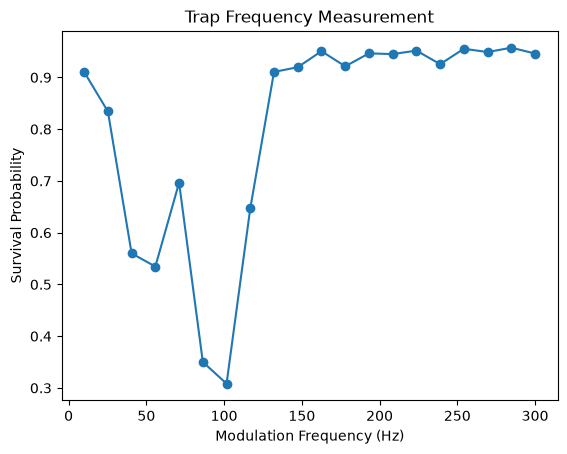

In [59]:
modfscan = np.linspace(minfscan, maxfscan, N_points)

plt.plot(modfscan, survival_probabilities, marker='o')
plt.xlabel('Modulation Frequency (Hz)')
plt.ylabel('Survival Probability')
plt.title('Trap Frequency Measurement')
plt.show()

## Fine Trap Frequency Scan

In [60]:
minflim = 10
maxflim = 300

minfscan = 10
maxfscan = 150
N_points = 20

modfscan = np.linspace(minfscan, maxfscan, N_points)
modvcfscan = np.linspace(frequency_to_voltage(minfscan, minflim, maxflim), frequency_to_voltage(maxfscan, minflim, maxflim), N_points)
survival_probabilities = []

for modvcf in modvcfscan:

    params["tImgCoolVCO1"] = 2.0
    params["tImgCoolVCO2"] = 2.0
    params["tImgCoolVVA1"] = exp_params["tImgCoolVVA"]
    params["tImgCoolVVA2"] = exp_params["tImgCoolVVA"]
    params["BackgroundDrop"] = 0
    params["TweezerModulation"] = 1
    params["tTweezerModulationVCF"] = modvcf
    params["tDelay2"] = 2000

    n_iterations = 20
    exp.set_motmaster_experiment("RbTweezerBasic2026_2")
    exp.set_iterations(1)
    hamcam.setup_acquisition(2)
    imgs1, imgs2 = [], []
    for i in range(n_iterations):
        hamcam.start_acquisition()
        exp.start_motmaster_experiment(params)
        img1, img2 = hamcam.acquire_n_frames(2, broadcast=True)
        imgs1.append(img1)
        imgs2.append(img2)

    survival_probability = an.extract_survival_probability(
        imgs1, imgs2, grid_positions, threshold="auto", window_size=5
    )

    survival_probabilities.append(survival_probability)

    print(f"Modulation frequency: {modvcf:.2f} V, Survival probability: {survival_probability:.4f}")

Modulation frequency: -10.00 V, Survival probability: 0.9077
Modulation frequency: -9.49 V, Survival probability: 0.9172
Modulation frequency: -8.98 V, Survival probability: 0.8828
Modulation frequency: -8.48 V, Survival probability: 0.6899
Modulation frequency: -7.97 V, Survival probability: 0.5233
Modulation frequency: -7.46 V, Survival probability: 0.4621
Modulation frequency: -6.95 V, Survival probability: 0.4160
Modulation frequency: -6.44 V, Survival probability: 0.7434
Modulation frequency: -5.93 V, Survival probability: 0.7742
Modulation frequency: -5.43 V, Survival probability: 0.5880
Modulation frequency: -4.92 V, Survival probability: 0.4202
Modulation frequency: -4.41 V, Survival probability: 0.3006
Modulation frequency: -3.90 V, Survival probability: 0.2825
Modulation frequency: -3.39 V, Survival probability: 0.3591
Modulation frequency: -2.89 V, Survival probability: 0.5531
Modulation frequency: -2.38 V, Survival probability: 0.7494
Modulation frequency: -1.87 V, Survival

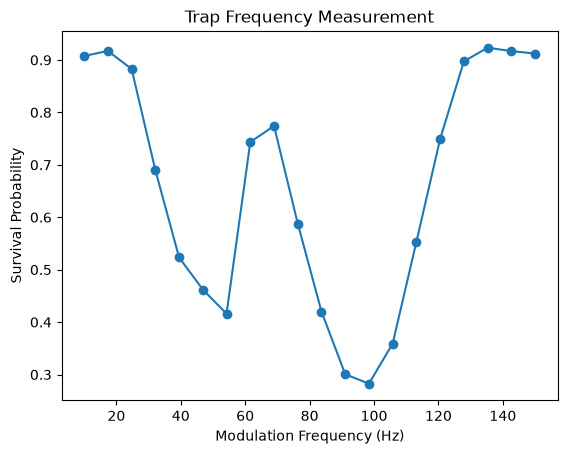

In [61]:
modfscan = np.linspace(minfscan, maxfscan, N_points)

plt.plot(modfscan, survival_probabilities, marker='o')
plt.xlabel('Modulation Frequency (Hz)')
plt.ylabel('Survival Probability')
plt.title('Trap Frequency Measurement')
plt.show()

## Finer Trap Frequency Scan

In [ ]:
minflim = 10
maxflim = 300

minfscan = 10
maxfscan = 150
N_points = 20

modfscan = np.linspace(minfscan, maxfscan, N_points)
modvcfscan = np.linspace(frequency_to_voltage(minfscan, minflim, maxflim), frequency_to_voltage(maxfscan, minflim, maxflim), N_points)
survival_probabilities = []

for modvcf in modvcfscan:

    params["tImgCoolVCO1"] = 2.0
    params["tImgCoolVCO2"] = 2.0
    params["tImgCoolVVA1"] = exp_params["tImgCoolVVA"]
    params["tImgCoolVVA2"] = exp_params["tImgCoolVVA"]
    params["BackgroundDrop"] = 0
    params["TweezerModulation"] = 1
    params["tTweezerModulationVCF"] = modvcf
    params["tDelay2"] = 2000
    
    exp.set_motmaster_experiment("RbTweezerBasic2026_2")
    exp.set_iterations(1)
    hamcam.setup_acquisition(2)
    imgs1, imgs2 = [], []
    for i in range(n_iterations):
        hamcam.start_acquisition()
        exp.start_motmaster_experiment(params)
        img1, img2 = hamcam.acquire_n_frames(2, broadcast=True)
        imgs1.append(img1)
        imgs2.append(img2)

    survival_probability = an.extract_survival_probability(
        imgs1, imgs2, grid_positions, threshold="auto", window_size=5
    )

    survival_probabilities.append(survival_probability)

    print(f"Modulation frequency: {modvcf:.2f} V, Survival probability: {survival_probability:.4f}")

Modulation frequency: -10.00 V, Survival probability: 0.9077
Modulation frequency: -9.49 V, Survival probability: 0.9172
Modulation frequency: -8.98 V, Survival probability: 0.8828
Modulation frequency: -8.48 V, Survival probability: 0.6899
Modulation frequency: -7.97 V, Survival probability: 0.5233
Modulation frequency: -7.46 V, Survival probability: 0.4621
Modulation frequency: -6.95 V, Survival probability: 0.4160
Modulation frequency: -6.44 V, Survival probability: 0.7434
Modulation frequency: -5.93 V, Survival probability: 0.7742
Modulation frequency: -5.43 V, Survival probability: 0.5880
Modulation frequency: -4.92 V, Survival probability: 0.4202
Modulation frequency: -4.41 V, Survival probability: 0.3006
Modulation frequency: -3.90 V, Survival probability: 0.2825
Modulation frequency: -3.39 V, Survival probability: 0.3591
Modulation frequency: -2.89 V, Survival probability: 0.5531
Modulation frequency: -2.38 V, Survival probability: 0.7494
Modulation frequency: -1.87 V, Survival

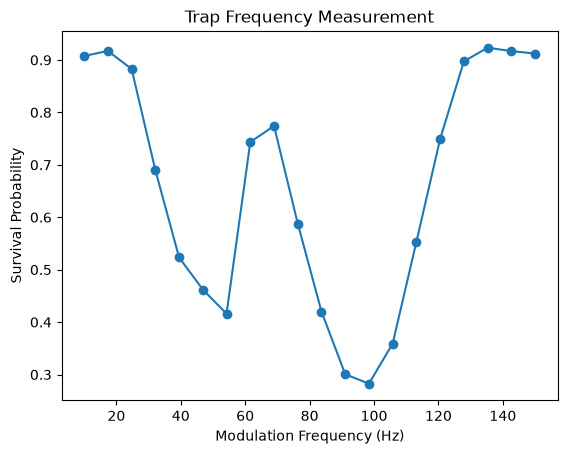

In [ ]:
modfscan = np.linspace(minfscan, maxfscan, N_points)

plt.plot(modfscan, survival_probabilities, marker='o')
plt.xlabel('Modulation Frequency (Hz)')
plt.ylabel('Survival Probability')
plt.title('Trap Frequency Measurement')
plt.show()